
# CS156 — Session 12: Linear Regression with Basis Functions

## Pre-Class Work: Yosemite Temperature Prediction

In this notebook, I explore how basis functions can improve linear regression when the relationship between the input and output is nonlinear. I use temperature measurements collected at five-minute intervals in Yosemite Village, California, from 2011 to 2016.

I first examine the limitations of ordinary linear regression; then, I use Gaussian radial basis functions (RBFs) to represent more complex temperature patterns. I apply ridge regression, evaluate performance using $R^2$ and mean absolute error (MAE), and compare a small number of hyperparameter settings.

**Main question:** Can transforming time into nonlinear features improve temperature predictions while keeping the model linear in its learned parameters?

I use separate training, validation, and test data so that the reported results reflect performance on observations not used to fit the model.



# Basic Questions for Class

## Question 1: Linearity in Parameters

A function is linear in its parameters when its weights appear only as coefficients in a sum, rather than being multiplied together or raised to powers.

For example:

$$
f(x)=w_0+w_1x+w_2x^2
$$

This function is linear in its parameters because each weight appears to the first power. However, it is nonlinear in the input variable $x$, since the function includes $x^2$.

This distinction matters because we can transform the input into nonlinear features while still using linear regression to estimate the weights.

## Question 2: Basis Functions

Basis functions transform the original input into new features, allowing the model to represent relationships that a straight line cannot capture.

**Absolute-distance basis function:**

$$
f(x)=w_0+w_1|x-c|
$$

The expression $|x-c|$ measures the distance between the input $x$ and a center $c$. Its shape is V-shaped, with a turning point at $c$.

**Polynomial basis function:**

$$
f(x)=w_0+w_1x+w_2x^2+w_3x^3+w_4x^4
$$

Polynomial basis functions use powers of the original input. They allow the model to represent curved relationships, although high-degree polynomials can become sensitive to noise.

In the practical exercises, I use Gaussian RBFs instead of absolute-distance functions because Gaussian functions provide smooth, localized features.

## Question 3: Ridge and Lasso Regularization

Ridge and lasso regression extend ordinary linear regression by penalizing large coefficients.

Ridge uses an L2 penalty:

$$
L_{\text{ridge}}=\sum_{i=1}^{n}(y_i-\hat{y}_i)^2+\lambda\sum_{j=1}^{p}w_j^2
$$

Lasso uses an L1 penalty:

$$
L_{\text{lasso}}=\sum_{i=1}^{n}(y_i-\hat{y}_i)^2+\lambda\sum_{j=1}^{p}|w_j|
$$

Ridge generally shrinks coefficients toward zero without making them exactly zero. Lasso can set some coefficients to zero, which effectively removes less useful features.

Both methods help control model complexity. This becomes especially important when basis functions create many new features.



# Core Questions

## Question 1: Describe the Variables in the Yosemite Temperature Dataset

The dataset comes from NOAA's U.S. Climate Reference Network and contains weather observations recorded every five minutes.

The original files contain measurements such as temperature, precipitation, solar radiation, surface temperature, humidity, soil conditions, and location information.

For this exercise, I focus on three columns:

- **UTC_DATE (column 1):** The measurement date, recorded as YYYYMMDD.
- **UTC_TIME (column 2):** The measurement time, recorded as HHmm.
- **AIR_TEMPERATURE (column 8):** The measured air temperature in degrees Celsius.

The column numbers are zero-indexed, as used in Python.

I convert the time into minutes since midnight, making it easier to use as a numerical input. I also extract the year and date information, which will help me examine seasonal patterns later.

### Data Loading and Cleaning

The original notebook attempted to read six files from the computer's local directory. However, those files were unavailable, causing a FileNotFoundError.

To fix this, I load the same Yosemite station files directly from NOAA. I combine the observations from 2011 to 2016 and remove missing temperature values.

This ensures that the models use actual temperature measurements rather than simulated observations.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import r2_score, mean_absolute_error

# Loading the Yosemite data directly from NOAA
frames = []

for year in range(2011, 2017):
    url = (f"https://www.ncei.noaa.gov/pub/data/uscrn/products/"
           f"subhourly01/{year}/CRNS0101-05-{year}-CA_Yosemite_Village_12_W.txt")

    year_data = pd.read_csv(url, sep=r"\s+", header=None, usecols=[1, 2, 8])
    year_data.columns = ["date", "clock", "temperature"]

    frames.append(year_data)
    print(f"Loaded {year}: {len(year_data):,} observations")

# Combining all six years
data = pd.concat(frames, ignore_index=True)

# Converting columns into their appropriate data types
data["date"] = pd.to_datetime(data["date"].astype(str), format="%Y%m%d", errors="coerce")
data["clock"] = pd.to_numeric(data["clock"], errors="coerce")
data["temperature"] = pd.to_numeric(data["temperature"], errors="coerce")

# Removing missing and invalid values
data = data.dropna(subset=["date", "clock", "temperature"]).copy()
data = data[(data["temperature"] > -1000) & (data["clock"] >= 0)].copy()
data = data[(data["clock"] // 100 < 24) & (data["clock"] % 100 < 60)].copy()

# Converting HHmm into minutes since midnight
clock = data["clock"].astype(int)
data["minutes"] = (clock // 100) * 60 + (clock % 100)

# Extracting the year for model evaluation
data["year"] = data["date"].dt.year

# Checking the cleaned dataset
print(f"\nTotal valid observations: {len(data):,}")
print("Years included:", sorted(data["year"].unique()))
display(data.head())


Loaded 2011: 105,120 observations
Loaded 2012: 105,408 observations
Loaded 2013: 105,120 observations
Loaded 2014: 105,120 observations
Loaded 2015: 105,120 observations
Loaded 2016: 105,408 observations

Total valid observations: 630,854
Years included: [np.int32(2011), np.int32(2012), np.int32(2013), np.int32(2014), np.int32(2015), np.int32(2016), np.int32(2017)]


,date,clock,temperature,minutes,year
0,2011-01-01,5,-6.4,5,2011
1,2011-01-01,10,-6.5,10,2011
2,2011-01-01,15,-6.5,15,2011
3,2011-01-01,20,-6.5,20,2011
4,2011-01-01,25,-6.7,25,2011



## Question 2: Explain Why the Linear Model Performs Poorly

The original code fits a straight line between time of day and temperature. It assumes that temperature changes at a constant rate throughout the day.

The linear model can be written as:

$$
\hat{T}=w_0+w_1t
$$

where:

- $\hat{T}$ is the predicted temperature.
- $t$ is the time in minutes since midnight.
- $w_0$ is the intercept.
- $w_1$ is the coefficient for time.

This assumption is restrictive because temperature does not follow a straight line. It usually rises during the day and falls at night; seasonal changes also create large differences between winter and summer.

A straight line cannot represent both the daily temperature cycle and the seasonal cycle. Weather conditions introduce further variation, making the relationship more complex.

I use this linear model as my baseline. To evaluate its performance, I train it on observations from 2011–2014 and reserve 2016 for final testing. I also reserve 2015 for selecting the RBF model's parameters.

This separation allows me to compare the models without evaluating them on their own training observations.


Training observations: 30,000
Validation observations: 10,000
Test observations: 10,000
Linear Regression R²: 0.0173
Linear Regression MAE: 6.46 °C


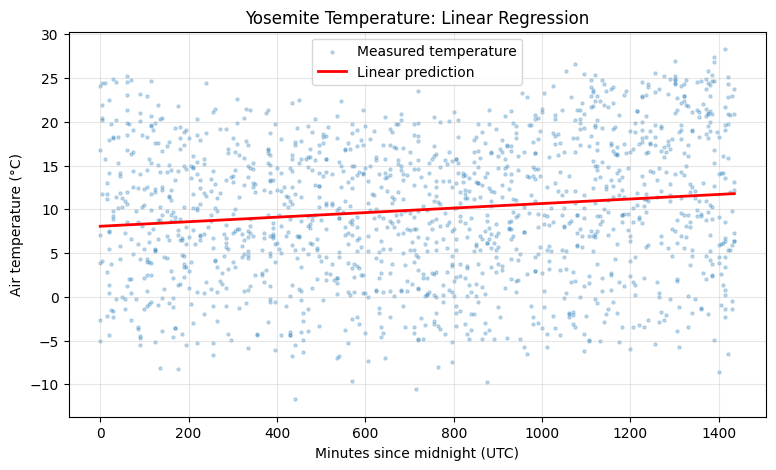

In [2]:

# Separating the data by year
train_all = data[data["year"] <= 2014]
valid_all = data[data["year"] == 2015]
test_all = data[data["year"] == 2016]

# Sampling observations to keep training manageable in Colab
train = train_all.sample(n=min(30000, len(train_all)), random_state=42).copy()
valid = valid_all.sample(n=min(10000, len(valid_all)), random_state=42).copy()
test = test_all.sample(n=min(10000, len(test_all)), random_state=42).copy()

# Selecting time of day as the only input
X_train_linear = train[["minutes"]]
y_train_linear = train["temperature"]

X_test_linear = test[["minutes"]]
y_test_linear = test["temperature"]

# Training ordinary linear regression
linear_model = LinearRegression()
linear_model.fit(X_train_linear, y_train_linear)

# Predicting temperatures on the test set
linear_predictions = linear_model.predict(X_test_linear)

# Measuring performance using R² and MAE
linear_r2 = r2_score(y_test_linear, linear_predictions)
linear_mae = mean_absolute_error(y_test_linear, linear_predictions)

print(f"Training observations: {len(train):,}")
print(f"Validation observations: {len(valid):,}")
print(f"Test observations: {len(test):,}")
print(f"Linear Regression R²: {linear_r2:.4f}")
print(f"Linear Regression MAE: {linear_mae:.2f} °C")

# Selecting a smaller sample for visualization
plot_data = train.sample(n=min(1500, len(train)), random_state=1)

# Creating predictions across the full day
line_times = pd.DataFrame({"minutes": [0, 1435]})
line_predictions = linear_model.predict(line_times)

# Plotting the measurements and the fitted straight line
plt.figure(figsize=(9, 5))
plt.scatter(plot_data["minutes"], plot_data["temperature"], s=5, alpha=0.25, label="Measured temperature")
plt.plot(line_times["minutes"], line_predictions, color="red", linewidth=2, label="Linear prediction")
plt.xlabel("Minutes since midnight (UTC)")
plt.ylabel("Air temperature (°C)")
plt.title("Yosemite Temperature: Linear Regression")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()



## Question 3: Apply Radial Basis Functions to Improve the Linear Model

The linear model cannot capture the curved and repeating patterns in temperature data, so I use Gaussian radial basis functions (RBFs) to transform the inputs.

A Gaussian RBF is defined as:

$$
\phi_j(x)=\exp\left(-\frac{(x-c_j)^2}{2\sigma^2}\right)
$$

Here, $c_j$ represents the center of the function, while $\sigma$ controls its width. Each RBF produces a smooth response that is strongest near its center and gradually decreases farther away.

Rather than using only time of day, I include both the time within the day and the position within the year. This allows the model to represent daily and seasonal temperature patterns.

For each combination of seasonal and daily centers, I construct a feature:

$$
\phi_{jk}(d,t)=\exp\left[-\frac{1}{2}\left(\frac{\Delta_d^2}{\sigma_d^2}+\frac{\Delta_t^2}{\sigma_t^2}\right)\right]
$$

In this equation:

- $d$ represents the position within the year.
- $t$ represents the time of day.
- $\Delta_d$ and $\Delta_t$ represent circular distances from the corresponding RBF centers.
- $\sigma_d$ and $\sigma_t$ control the widths of the seasonal and daily functions.

I use circular distances because December is close to January, just as midnight is close to the end of the previous day.

After constructing these features, I apply ridge regression:

$$
\hat{T}(d,t)=w_0+\sum_{j=1}^{m}\sum_{k=1}^{q}w_{jk}\phi_{jk}(d,t)
$$

The model remains linear in its learned coefficients, even though the relationship between time and temperature is now nonlinear.

I start with eight seasonal centers and six daily centers, giving 48 RBF features. Ridge regularization helps control the model's complexity and reduces the effect of highly correlated features.


In [3]:

# Creating Gaussian RBF features for seasonal and daily cycles
def make_rbf_features(frame, n_season, n_day, season_width, day_width):

    # Converting calendar dates into fractions of a year
    day_number = frame["date"].dt.dayofyear.to_numpy() - 1
    year_days = np.where(frame["date"].dt.is_leap_year.to_numpy(), 366.0, 365.0)
    season = day_number / year_days

    # Converting minutes into fractions of a day
    day_time = frame["minutes"].to_numpy() / 1440.0

    # Placing RBF centers evenly along both cycles
    season_centers = np.linspace(0, 1, n_season, endpoint=False)
    day_centers = np.linspace(0, 1, n_day, endpoint=False)

    # Measuring circular distances from the centers
    season_distance = np.abs(season[:, None] - season_centers[None, :])
    season_distance = np.minimum(season_distance, 1 - season_distance)

    day_distance = np.abs(day_time[:, None] - day_centers[None, :])
    day_distance = np.minimum(day_distance, 1 - day_distance)

    # Converting distances into Gaussian RBF features
    season_rbf = np.exp(-0.5 * (season_distance / season_width) ** 2)
    day_rbf = np.exp(-0.5 * (day_distance / day_width) ** 2)

    # Combining seasonal and daily features
    features = (season_rbf[:, :, None] * day_rbf[:, None, :]).reshape(len(frame), -1)

    return features


# Defining the initial RBF settings
initial = {
    "n_season": 8,
    "n_day": 6,
    "season_width": 0.12,
    "day_width": 0.18,
    "alpha": 1.0}

# Separating basis-function settings from ridge regularization
feature_params = {k: v for k, v in initial.items() if k != "alpha"}

# Transforming training and validation observations
X_train_rbf = make_rbf_features(train, **feature_params)
X_valid_rbf = make_rbf_features(valid, **feature_params)

# Training ridge regression on the transformed features
rbf_model = Ridge(alpha=initial["alpha"])
rbf_model.fit(X_train_rbf, train["temperature"])

# Evaluating the RBF model on validation observations
valid_predictions = rbf_model.predict(X_valid_rbf)

initial_r2 = r2_score(valid["temperature"], valid_predictions)
initial_mae = mean_absolute_error(valid["temperature"], valid_predictions)

print(f"Number of RBF features: {X_train_rbf.shape[1]}")
print(f"Initial RBF Validation R²: {initial_r2:.4f}")
print(f"Initial RBF Validation MAE: {initial_mae:.2f} °C")


Number of RBF features: 48
Initial RBF Validation R²: 0.5438
Initial RBF Validation MAE: 4.21 °C



## Question 4: Choose a Metric and Evaluate Model Performance

I use the coefficient of determination ($R^2$) to evaluate how well the model explains variation in temperature. I also calculate mean absolute error (MAE), which measures the average size of prediction errors in degrees Celsius.

The equations are:

$$
R^2=1-\frac{\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}{\sum_{i=1}^{n}(y_i-\bar{y})^2}
$$

$$
MAE=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|
$$

A higher $R^2$ indicates better predictive performance, while a lower MAE indicates smaller average errors.

An $R^2$ of zero means the model performs as well as predicting the evaluation set's mean. A negative value means that the model performs worse than this constant prediction.

I previously obtained an $R^2$ close to 0.9957, but that result came from fitting and evaluating a model on a small set of simulated observations. It did not measure performance on the actual Yosemite dataset.

In this revised implementation, I use real temperature measurements and separate the data by year. I report validation performance while selecting parameters, followed by test performance on observations that were not used for training or tuning.

This provides a more reliable assessment of whether the RBF transformation improves temperature prediction.



# Extension Questions

## Question 1: Search the RBF Hyperparameters and Report the Best Performance

The assignment provides an approximate reference $R^2$ of 0.82 and asks us to improve the RBF model by adjusting its hyperparameters.

The main hyperparameters are:

- **Number of RBF centers:** Determines how many local patterns the model can represent.
- **Center positions:** Determine where each RBF reaches its maximum response.
- **RBF width:** Controls how broadly each feature responds to nearby observations.
- **Ridge alpha:** Controls the regularization penalty and the size of the learned coefficients.

The model learns the coefficients, or heights, of the RBF features during regression.

A small number of RBFs may fail to capture important temperature patterns. However, using too many narrow functions may make the model unnecessarily complex and sensitive to noise.

I use a simple manual search with four parameter combinations. Each combination changes the number of seasonal centers, daily centers, and their widths, as well as the ridge regularization strength.

I select the model with the highest validation $R^2$ on 2015 observations. After selecting the parameters, I evaluate the model on the separate 2016 test set.

The reference score of 0.82 is not a strict maximum; my goal is to find a reasonable model and report its actual performance, rather than force the score to match the benchmark.


In [4]:

# Defining a small set of RBF hyperparameters
settings = [
    {"n_season": 6, "n_day": 4, "season_width": 0.17, "day_width": 0.22, "alpha": 1.0},
    {"n_season": 8, "n_day": 6, "season_width": 0.12, "day_width": 0.18, "alpha": 1.0},
    {"n_season": 12, "n_day": 8, "season_width": 0.08, "day_width": 0.13, "alpha": 1.0},
    {"n_season": 16, "n_day": 8, "season_width": 0.06, "day_width": 0.12, "alpha": 5.0}
]

# Preparing variables to track model performance
results = []
best_valid_r2 = -np.inf
best_params = None

# Evaluating each parameter combination
for params in settings:

    # Extracting parameters used to construct the RBF features
    feature_params = {k: v for k, v in params.items() if k != "alpha"}

    # Transforming the training and validation data
    X_train = make_rbf_features(train, **feature_params)
    X_valid = make_rbf_features(valid, **feature_params)

    # Fitting ridge regression on the transformed training data
    model = Ridge(alpha=params["alpha"])
    model.fit(X_train, train["temperature"])

    # Calculating validation R²
    predictions = model.predict(X_valid)
    score = r2_score(valid["temperature"], predictions)

    # Recording the parameters and their performance
    results.append({**params, "n_features": X_train.shape[1], "validation_r2": score})

    # Keeping the settings with the highest validation R²
    if score > best_valid_r2:
        best_valid_r2 = score
        best_params = params.copy()

# Displaying the parameter search results
results_table = pd.DataFrame(results).sort_values("validation_r2", ascending=False)

display(results_table)
print("Best Parameters:", best_params)
print(f"Best Validation R²: {best_valid_r2:.4f}")

# Preparing the best RBF features for final testing
best_features = {k: v for k, v in best_params.items() if k != "alpha"}

X_train_best = make_rbf_features(train, **best_features)
X_test_best = make_rbf_features(test, **best_features)

# Training the selected model on the training data
best_model = Ridge(alpha=best_params["alpha"])
best_model.fit(X_train_best, train["temperature"])

# Evaluating the selected model on the untouched test year
test_predictions = best_model.predict(X_test_best)

best_r2 = r2_score(test["temperature"], test_predictions)
best_mae = mean_absolute_error(test["temperature"], test_predictions)

# Comparing the final model against ordinary linear regression
print("\n--- Final Model Comparison ---")
print(f"Linear Regression Test R²: {linear_r2:.4f}")
print(f"RBF Ridge Test R²: {best_r2:.4f}")
print(f"Linear Regression Test MAE: {linear_mae:.2f} °C")
print(f"RBF Ridge Test MAE: {best_mae:.2f} °C")
print(f"Improvement in Test R²: {best_r2 - linear_r2:+.4f}")


,n_season,n_day,season_width,day_width,alpha,n_features,validation_r2
3,16,8,0.06,0.12,5.0,128,0.550126
2,12,8,0.08,0.13,1.0,96,0.546431
1,8,6,0.12,0.18,1.0,48,0.543821
0,6,4,0.17,0.22,1.0,24,0.525619


Best Parameters: {'n_season': 16, 'n_day': 8, 'season_width': 0.06, 'day_width': 0.12, 'alpha': 5.0}
Best Validation R²: 0.5501

--- Final Model Comparison ---
Linear Regression Test R²: 0.0173
RBF Ridge Test R²: 0.6100
Linear Regression Test MAE: 6.46 °C
RBF Ridge Test MAE: 3.99 °C
Improvement in Test R²: +0.5928



## Question 1: Visualizing the Best RBF Model

To understand the predictions, I compare the ordinary linear regression model with the selected RBF ridge model.

I choose one day from the 2016 test year and plot the measured temperatures alongside both model predictions.

The linear model produces a straight line because it uses time of day without transforming the input. The RBF model can produce a curved temperature profile because it combines several nonlinear features.

I expect the RBF model to represent typical daily and seasonal patterns more effectively. However, it may still miss unexpected temperature changes caused by weather conditions, because these are not included as input features.

The plot helps me interpret the shape of the predictions; the test $R^2$ and MAE provide the quantitative comparison.


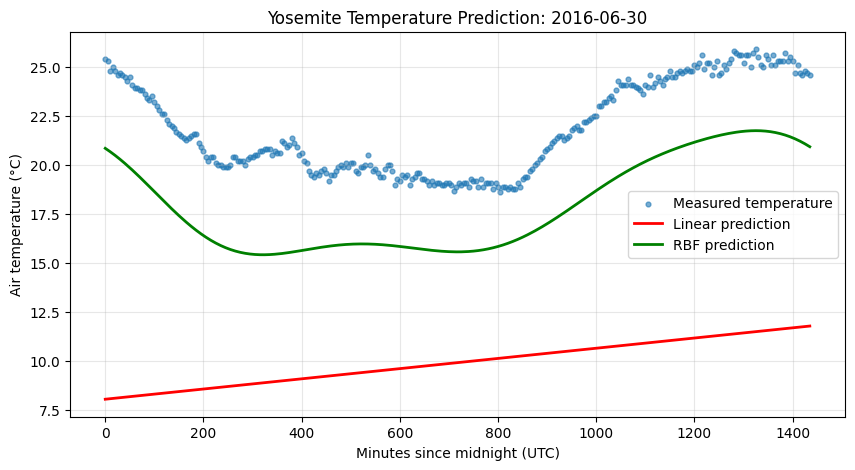

In [5]:

# Selecting a day from the 2016 test year
plot_day = test["date"].sort_values().iloc[len(test) // 2]

# Extracting all available measurements for that day
observed_day = data[data["date"] == plot_day].copy()

# Creating five-minute prediction intervals across the day
plot_frame = pd.DataFrame({
    "date": [plot_day] * 288,
    "minutes": np.arange(0, 1440, 5)})

# Generating predictions from the original linear model
linear_curve = linear_model.predict(plot_frame[["minutes"]])

# Generating predictions from the selected RBF model
X_plot_rbf = make_rbf_features(plot_frame, **best_features)
rbf_curve = best_model.predict(X_plot_rbf)

# Comparing the measurements and model predictions
plt.figure(figsize=(10, 5))
plt.scatter(observed_day["minutes"], observed_day["temperature"], s=12, alpha=0.6, label="Measured temperature")
plt.plot(plot_frame["minutes"], linear_curve, color="red", linewidth=2, label="Linear prediction")
plt.plot(plot_frame["minutes"], rbf_curve, color="green", linewidth=2, label="RBF prediction")

plt.xlabel("Minutes since midnight (UTC)")
plt.ylabel("Air temperature (°C)")
plt.title(f"Yosemite Temperature Prediction: {plot_day.date()}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()



## Question 2: Explain What Applying Lasso to the Model Might Do

Applying lasso would introduce an L1 penalty on the coefficients learned for the RBF features.

The objective function would become:

$$
\min_{w_0,\mathbf{w}}\left[\frac{1}{2n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2+\alpha\sum_{j=1}^{p}|w_j|\right]
$$

Unlike ridge regression, which generally shrinks coefficients toward zero, lasso can set some coefficients exactly to zero.

In this model, each coefficient corresponds to an RBF feature representing a particular combination of season and time of day. If lasso sets a coefficient to zero, that feature no longer contributes directly to the prediction.

This could simplify the model by reducing the number of active RBF features. It might also reduce overfitting, especially when several nearby RBFs represent similar patterns.

However, there is a trade-off. If the penalty is too strong, lasso may remove features that capture useful temperature variation, reducing predictive accuracy.

I would therefore select the lasso penalty using validation data rather than assuming that a simpler model will always perform better.


In [6]:

# Reporting the selected RBF model's performance
print("QUESTION 1: RBF PERFORMANCE\n")

print(
    f"I compared ordinary linear regression with a Gaussian RBF "
    f"model using Yosemite temperature measurements from 2011 "
    f"to 2016. I selected the RBF parameters using 2015 validation "
    f"data and evaluated the final model on 2016 test data. "
    f"The linear model achieved an R² of {linear_r2:.4f}, "
    f"while the RBF model achieved an R² of {best_r2:.4f}. "
    f"The RBF model's MAE was {best_mae:.2f} °C.")

print("\nSELECTED PARAMETERS\n")

print(f"Seasonal Centers: {best_params['n_season']}")
print(f"Daily Centers: {best_params['n_day']}")
print(f"Total RBF Features: {best_params['n_season'] * best_params['n_day']}")
print(f"Seasonal Width: {best_params['season_width']}")
print(f"Daily Width: {best_params['day_width']}")
print(f"Ridge Alpha: {best_params['alpha']}")

print("\nQUESTION 2: EFFECT OF LASSO\n")

print(
    "Applying lasso could set some RBF coefficients exactly to "
    "zero, reducing the number of features that contribute to "
    "the predictions. This could simplify the model and reduce "
    "overfitting. However, a strong penalty might also remove "
    "useful temperature patterns and reduce predictive accuracy.")


QUESTION 1: RBF PERFORMANCE

I compared ordinary linear regression with a Gaussian RBF model using Yosemite temperature measurements from 2011 to 2016. I selected the RBF parameters using 2015 validation data and evaluated the final model on 2016 test data. The linear model achieved an R² of 0.0173, while the RBF model achieved an R² of 0.6100. The RBF model's MAE was 3.99 °C.

SELECTED PARAMETERS

Seasonal Centers: 16
Daily Centers: 8
Total RBF Features: 128
Seasonal Width: 0.06
Daily Width: 0.12
Ridge Alpha: 5.0

QUESTION 2: EFFECT OF LASSO

Applying lasso could set some RBF coefficients exactly to zero, reducing the number of features that contribute to the predictions. This could simplify the model and reduce overfitting. However, a strong penalty might also remove useful temperature patterns and reduce predictive accuracy.
